In [4]:
import time
from pathlib import Path
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
RAW = ROOT / "data" / "raw"; RAW.mkdir(parents=True, exist_ok=True)
GRID, HOURS, ROAD_THRESH = 8, 72, 0.7     # 0.7 = value picked by calibration earlier


def build_graph(rng, grid=GRID):
    G = nx.grid_2d_graph(grid, grid)
    nodes = list(G.nodes)
    rng.shuffle(nodes)
    shelters, depots = set(nodes[:8]), set(nodes[8:11])
    slope = rng.uniform(-1, 1, size=2)
    for (x, y) in G.nodes:
        elev = 5 + slope[0] * x / grid * 3 + slope[1] * y / grid * 3 + rng.normal(0, 0.4)
        G.nodes[(x, y)]["elevation"] = elev
        if (x, y) in shelters:
            G.nodes[(x, y)].update(ntype="shelter", population=0,
                                   capacity=int(rng.integers(2500, 7000)), inventory=0.0)
        elif (x, y) in depots:
            G.nodes[(x, y)].update(ntype="depot", population=0, capacity=0,
                                   inventory=float(rng.integers(8000, 20000)))
        else:
            pop = int(rng.integers(500, 4000))
            days = rng.uniform(1.5, 6.0)
            G.nodes[(x, y)].update(ntype="zone", population=pop, capacity=0,
                                   inventory=pop * 0.01 * 24 * days)
    for u, v in G.edges:
        G.edges[u, v]["length_km"] = float(rng.uniform(0.8, 2.5))
    return G


def make_rainfall(rng, hours=HOURS):
    t = np.arange(hours)
    base = rng.gamma(1.5, 0.6, size=hours)
    peak_t = rng.integers(12, 40)
    width = rng.uniform(4, 10)
    intensity = rng.uniform(15, 55)
    return base + intensity * np.exp(-0.5 * ((t - peak_t) / width) ** 2)


def add_failure_labels(df, horizon=6):
    # no groupby().apply(): new pandas drops the group columns
    df = df.sort_values(["scenario", "node", "hour"]).reset_index(drop=True)
    df["failed_now"] = ((df["isolated"] == 1) |
                        (df["days_of_supply"] < 0.25) |
                        (df["nearest_shelter_occ"] > 1.0)).astype(int)
    failed = df["failed_now"].to_numpy()
    tt = np.zeros(len(df))
    for idx in df.groupby(["scenario", "node"]).indices.values():
        f = failed[idx]
        T = len(f)
        out = np.full(T, float(T))          # censored: no failure observed
        nxt = None
        for i in range(T - 1, -1, -1):
            if f[i]:
                nxt = i
            if nxt is not None:
                out[i] = nxt - i
        tt[idx] = out
    df["hours_to_failure"] = tt
    df["will_fail_within_6h"] = (tt <= horizon).astype(int)
    return df


def run_simulation(seed, interventions=None, hours=HOURS, road_thresh=ROAD_THRESH):
    rng = np.random.default_rng(seed)
    G = build_graph(rng)
    rain = make_rainfall(rng, hours)
    interventions = interventions or {}

    for node, amt in interventions.get("extra_supply", {}).items():
        if node in G.nodes:
            G.nodes[node]["inventory"] += amt
    for node in interventions.get("open_shelter", []):
        if node in G.nodes:
            G.nodes[node].update(ntype="shelter", capacity=4000)
    forced_open = set(map(frozenset, interventions.get("restore_roads", [])))

    nodes = list(G.nodes)
    depth = {n: 0.0 for n in nodes}
    occupancy = {n: 0 for n in nodes}
    inventory = {n: G.nodes[n]["inventory"] for n in nodes}
    displaced_total = {n: 0 for n in nodes}
    rows = []

    for h in range(hours):
        new_depth = {}
        for n in nodes:
            nb = [depth[m] for m in G.neighbors(n)]
            inflow = rain[h] / 1000 * (1.0 + max(0, 5.2 - G.nodes[n]["elevation"]))
            spread = 0.15 * (np.mean(nb) - depth[n]) if nb else 0.0
            drain = 0.03 * depth[n] + 0.01
            new_depth[n] = max(0.0, depth[n] + inflow + spread - drain)
        depth = new_depth

        for u, v in G.edges:
            avg = (depth[u] + depth[v]) / 2
            G.edges[u, v]["failed"] = bool(avg > road_thresh and frozenset((u, v)) not in forced_open)

        open_G = nx.Graph([(u, v) for u, v in G.edges if not G.edges[u, v]["failed"]])
        open_G.add_nodes_from(nodes)
        shelters = [n for n in nodes if G.nodes[n]["ntype"] == "shelter"]

        comp = {}
        for i, c in enumerate(nx.connected_components(open_G)):
            for n in c:
                comp[n] = i
        shelter_comps = {comp[s] for s in shelters}

        hour_rows = []
        for n in nodes:
            nd = G.nodes[n]
            if nd["ntype"] != "zone":
                continue
            frac = min(1.0, max(0.0, (depth[n] - 0.3) / 1.5))
            displaced = int(nd["population"] * frac)
            newly = max(0, displaced - displaced_total[n])
            displaced_total[n] = max(displaced_total[n], displaced)
            requests = int(rng.poisson(0.002 * nd["population"] * depth[n] * 3))

            consumption = (nd["population"] + 0.5 * displaced) * 0.01
            inventory[n] = max(0.0, inventory[n] - consumption)
            base_daily = max(nd["population"] * 0.01 * 24, 1e-9)

            nearest, dist = None, np.inf
            if comp[n] in shelter_comps:
                cands = [s for s in shelters if comp[s] == comp[n]]
                nearest = min(cands, key=lambda s: nx.shortest_path_length(open_G, n, s))
                dist = nx.shortest_path_length(open_G, n, nearest)
                if newly > 0:
                    occupancy[nearest] += newly

            open_roads = sum(not G.edges[n, m]["failed"] for m in G.neighbors(n))
            hour_rows.append(dict(
                scenario=seed, hour=h, node=f"{n[0]}_{n[1]}", x=n[0], y=n[1],
                population=nd["population"], elevation=nd["elevation"],
                rain_mm=rain[h], flood_depth=depth[n],
                displaced=displaced, requests=requests,
                inventory=inventory[n],
                days_of_supply=inventory[n] / base_daily,
                open_road_frac=open_roads / max(1, G.degree(n)),
                isolated=int(nearest is None),
                shelter_dist=dist if np.isfinite(dist) else 99,
                nearest_shelter_occ=0.0,
                _shelter=nearest,
            ))

        # each zone gets the occupancy of its OWN nearest shelter (not the global max)
        ratio = {s: occupancy[s] / max(1, G.nodes[s]["capacity"]) for s in shelters}
        for r in hour_rows:
            s = r.pop("_shelter")
            r["nearest_shelter_occ"] = ratio[s] if s is not None else 0.0
        rows.extend(hour_rows)

    return add_failure_labels(pd.DataFrame(rows))


print("simulator ready:", callable(run_simulation), "| data folder:", RAW)

simulator ready: True | data folder: /home/ibm-user/floodguard/data/raw


0.6s | shape: (3816, 20)


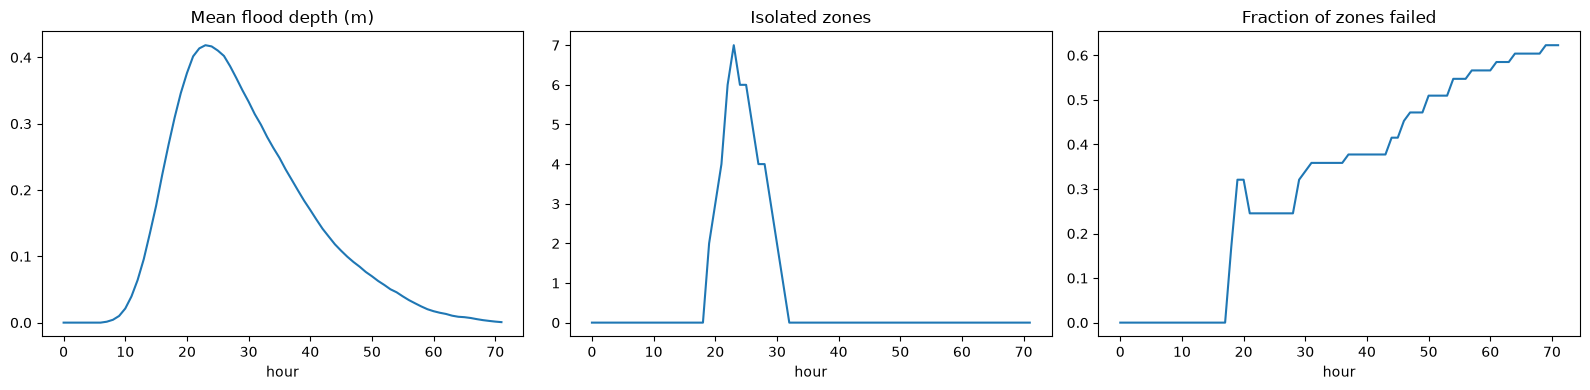

Failure rate: 0.327 | max isolated: 7


In [5]:
t0 = time.time()
df1 = run_simulation(seed=0)
print(f"{time.time()-t0:.1f}s | shape: {df1.shape}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df1.groupby("hour")["flood_depth"].mean().plot(ax=ax[0], title="Mean flood depth (m)")
df1.groupby("hour")["isolated"].sum().plot(ax=ax[1], title="Isolated zones")
df1.groupby("hour")["failed_now"].mean().plot(ax=ax[2], title="Fraction of zones failed")
plt.tight_layout(); plt.show()
print("Failure rate:", round(df1["failed_now"].mean(), 3), "| max isolated:", df1.groupby("hour")["isolated"].sum().max())

In [7]:
t0 = time.time()
frames = []
for seed in range(200):
    frames.append(run_simulation(seed))
    if (seed + 1) % 20 == 0:
        print(f"{seed+1}/200 | {time.time()-t0:.0f}s")
sim = pd.concat(frames, ignore_index=True)
print(sim.shape, "| scenarios:", sim["scenario"].nunique())

try:
    sim.to_parquet(RAW / "sim_runs.parquet", index=False)
    print("saved parquet")
except Exception:
    sim.to_csv(RAW / "sim_runs.csv", index=False)       # fallback if pyarrow is missing
    print("saved CSV")

print(sim[["failed_now", "will_fail_within_6h", "isolated"]].mean().round(3))
print("NaNs:", int(sim.isna().sum().sum()))

20/200 | 11s
40/200 | 23s
60/200 | 35s
80/200 | 46s
100/200 | 57s
120/200 | 68s
140/200 | 79s
160/200 | 89s
180/200 | 100s
200/200 | 111s
(763200, 20) | scenarios: 200
saved CSV
failed_now             0.272
will_fail_within_6h    0.326
isolated               0.095
dtype: float64
NaNs: 0
